In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy as sp

In [2]:
df = pd.read_csv('flights.csv')

In [3]:
df.head()

,flt_id,dof,adep,ades,model,icao_operator,duration_min,delay_min
0,RYR404A,2025-01-11,LPPR,LEBL,Boeing 737 MAX 8-200,RYR,83.333333,-2.333333
1,DLH3AK,2025-01-17,EDDF,EPKK,A320-214,DLH,84.166667,12.333333
2,AFR1405,2025-01-13,LIRF,LFPG,A320 214,AFR,102.250000,-0.750000
3,AFR7464,2025-01-14,LFPG,LFMT,A320 214,AFR,61.750000,-0.083333
4,DLH81P,2025-01-21,LFMN,EDDF,A320 214,DLH,76.000000,0.416667


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 965425 entries, 0 to 965424
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   flt_id         965407 non-null  str    
 1   dof            965425 non-null  str    
 2   adep           965425 non-null  str    
 3   ades           965425 non-null  str    
 4   model          941784 non-null  str    
 5   icao_operator  965425 non-null  str    
 6   duration_min   965425 non-null  float64
 7   delay_min      965425 non-null  float64
dtypes: float64(2), str(6)
memory usage: 97.1 MB


flt_id - id рейса

dof - дата рейса

adep - аэродром вылета

ades - аэродром прилёта

model - модель самолёта

icao_operator - компания

duration_min - длительность полёта в минутах

delay_min - задержка прилёта в минутах

# 1. Познакомтесь с данными и ответьте на вопросы
Используйте визуализации: графики, таблицы, сводные таблицы.

1. За какой период представлены данные?

In [5]:
print(f"Данные представлены за период с {df['dof'].min()} по {df['dof'].max()}")

Данные представлены за период с 2025-01-02 по 2025-12-31


2. Сколько авиакомпаний рассматриваются?

In [6]:
icao_operators_set = pd.unique(df['icao_operator'])
print(f"Количество рассматриваемых авиакомпаний: {len(icao_operators_set)}")

Количество рассматриваемых авиакомпаний: 7


3. Сколько уникальных аэропортов и уникальных маршрутов?

In [7]:
aerodromes_amount = pd.unique(pd.concat([df['adep'], df['ades']])).shape[0]
routes_amount = df[['adep', 'ades']].drop_duplicates().shape[0]

print(f"Количество аэропортов: {aerodromes_amount}")
print(f"Количество уникальных маршрутов: {routes_amount}")

Количество аэропортов: 82
Количество уникальных маршрутов: 3585


4. Для каждой авиакомпании выведите топ 5 самых популярных маршрутов?

In [8]:
flt_top = (
    df.groupby(['icao_operator', 'adep', 'ades'])
        .size()
        .reset_index(name='flt_amount')
        .sort_values(['icao_operator', 'flt_amount'], ascending=[True, False])
        .groupby('icao_operator')
        .head(5)
)
print(flt_top)

     icao_operator  adep  ades  flt_amount
119            AFR  LFMN  LFPO        3333
225            AFR  LFPO  LFMN        3323
222            AFR  LFPO  LFBO        3167
98             AFR  LFBO  LFPO        3163
193            AFR  LFPG  LFMN        2636
432            BAW  EGPH  EGLL        3099
376            BAW  EGLL  EGPH        3088
428            BAW  EGPF  EGLL        2898
375            BAW  EGLL  EGPF        2897
378            BAW  EGLL  EHAM        2482
572            DLH  EDDF  EDDB        4368
574            DLH  EDDF  EDDH        4087
577            DLH  EDDF  EDDM        4064
541            DLH  EDDB  EDDF        4005
589            DLH  EDDF  EGLL        4000
1390           EZY  EGCC  EHAM        1208
1723           EZY  EHAM  EGCC        1205
1679           EZY  EGPH  EGKK        1189
1574           EZY  EGKK  EGPH        1188
1726           EZY  EHAM  EGGW        1182
2918           RYR  EGSS  EIDW        1863
2976           RYR  EIDW  EGSS        1842
2971       

5. Для каждой авиакомпании выведите топ 5 самых долгих и топ 5 самых коротких маршрутов?

In [9]:
routes = (
    df.groupby(['icao_operator', 'adep', 'ades'])['duration_min']
        .mean()
        .reset_index(name='avg_duration')
        .sort_values(['icao_operator', 'avg_duration'], ascending=[True, False])
        .groupby('icao_operator')
)

print(routes.head(5))
print(routes.tail(5))

     icao_operator  adep  ades  avg_duration
283            AFR  LROP  LFLL    453.500000
243            AFR  LHBP  LFMN    440.333333
68             AFR  LCLK  LFPG    262.375000
21             AFR  EDDV  EDDF    233.333333
182            AFR  LFPG  LCLK    225.458333
477            BAW  LFMN  EHAM    447.583333
451            BAW  LCLK  EGLL    275.949784
450            BAW  LCLK  EGKK    272.124167
531            BAW  LTAI  EGKK    251.495955
337            BAW  EGKK  LCLK    247.129526
886            DLH  EGPH  EDDP    360.750000
1082           DLH  LFPB  LYBE    298.333333
1223           DLH  LYBE  LPPT    266.000000
997            DLH  LCLK  EDDL    240.750000
688            DLH  EDDL  EDDK    236.166667
1797           EZY  LCLK  EGAA    313.808333
1804           EZY  LCLK  EGPF    306.863333
2511           EZY  LTAI  EGAA    287.947368
1801           EZY  LCLK  EGGP    286.890805
1799           EZY  LCLK  EGCC    283.492424
3133           RYR  EPWA  LEMD    281.333333
3181      

6. Какая авиакомпания лидирует по числу перевозок?

In [10]:
operators_top = (
    df.groupby(['icao_operator'])
        .size()
        .reset_index(name='flt_amount')
        .sort_values(['flt_amount'], ascending=[False])
)
print(operators_top.iloc[0])

icao_operator       DLH
flt_amount       226617
Name: 2, dtype: object


7. Выведите топ 10 аэропортов из которых больше всего построено маршрутов?

In [11]:
top_airport = (
    df.groupby(['adep'])['ades']
        .nunique()
        .reset_index(name='routes_amount')
        .sort_values(['routes_amount'], ascending=[False])
        .head(10)
)

print(top_airport)

    adep  routes_amount
3   EDDF             72
18  EGCC             70
29  EGSS             68
60  LHBP             68
7   EDDM             68
1   EDDB             67
28  EGPH             66
43  LEBL             66
61  LIMC             66
55  LFPG             66


8. Для каждого маршрута оцените среднее и медианное время полета?

In [12]:
routes_stats = (df.groupby(['adep', 'ades'])['duration_min']
                    .agg(['mean', 'median'])
                    .reset_index()
                    .rename(columns={'mean': 'avg_duration', 'median': 'median_duration'})
)
print(routes_stats)

      adep  ades  avg_duration  median_duration
0     EBBR  EDDB     66.268229        66.416667
1     EBBR  EDDF     40.738137        39.750000
2     EBBR  EDDM     61.923721        61.375000
3     EBBR  EDDW     55.333333        55.333333
4     EBBR  EGCC     74.750000        74.750000
...    ...   ...           ...              ...
3580  LYBE  LPPT    221.078704       220.625000
3581  LYBE  LROP     47.583333        47.583333
3582  LYBE  LSGG    103.869048       104.583333
3583  LYBE  LTFJ     84.250000        81.916667
3584  LYBE  LTFM     80.505098        79.000000

[3585 rows x 4 columns]


9. Какой маршрут наиболее "непредсказуемый" по времени полета?

In [13]:
routes_std = (df.groupby(['adep', 'ades'])['duration_min']
                    .std()
                    .reset_index(name='std')
                    .sort_values(['std'], ascending=[False])
)
print(routes_std.iloc[0])

adep         LFSB
ades         LIMC
std     87.826743
Name: 2491, dtype: object


10. Проанализируйте, как день недели, месяц и другие временные признаки влияют на число полетов?

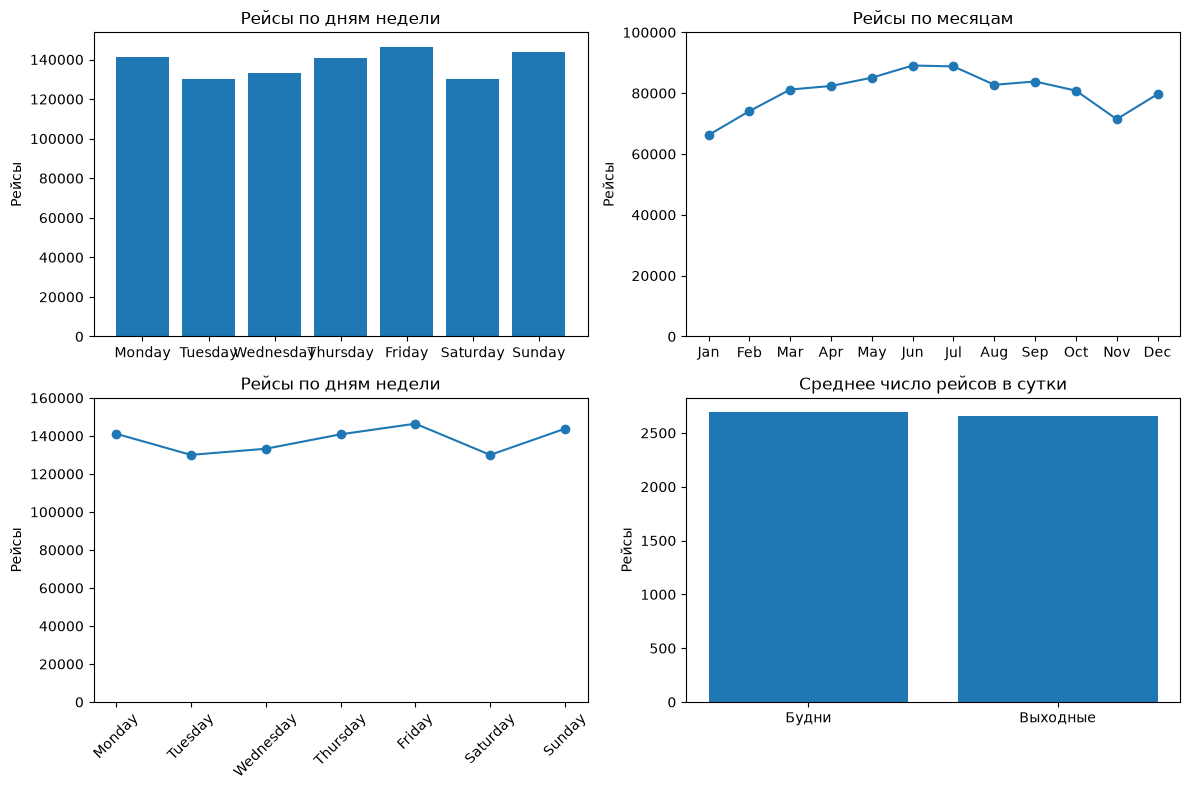

In [14]:
df['dof'] = pd.to_datetime(df['dof'])

df['weekday'] = df['dof'].dt.day_name()
df['month'] = df['dof'].dt.month
df['is_weekend'] = df['dof'].dt.weekday >= 5

weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday',
                 'Friday', 'Saturday', 'Sunday']
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

by_weekday = df.groupby('weekday').size().reindex(weekday_order)
by_month = df.groupby('month').size().reindex(range(1, 13), fill_value=0)

per_day = df.groupby(df['dof'].dt.date).size()
avg_per_day = per_day.groupby(pd.to_datetime(per_day.index).weekday >= 5).mean()
avg_per_day.index = ['Будни', 'Выходные']



fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].bar(weekday_order, by_weekday.values)
axes[0, 0].set_title('Рейсы по дням недели')

axes[0, 1].plot(month_names, by_month.values, marker='o')
axes[0, 1].set_title('Рейсы по месяцам')
axes[0, 1].set_ylim([0, 100000])

axes[1, 0].plot(weekday_order, by_weekday.values, marker='o')
axes[1, 0].set_title('Рейсы по дням недели')
axes[1, 0].tick_params(axis='x', rotation=45)
axes[1, 0].set_ylim([0, 160000])

axes[1, 1].bar(avg_per_day.index, avg_per_day.values)
axes[1, 1].set_title('Среднее число рейсов в сутки')

for ax in axes.flat:
    ax.set_ylabel('Рейсы')

plt.tight_layout()
plt.show()

df = df.drop(columns=['weekday', 'month', 'is_weekend'])

11. Для маршрутов по которым летают несколько авиакомпаний, сравните какая из них в среднем летает быстрее?

In [15]:
avg = df.groupby(['adep','ades','icao_operator'])['duration_min'].mean().reset_index()

# больше одной авиакомпании на маршрут
multi = avg[avg.groupby(['adep','ades'])['icao_operator'].transform('size') > 1]

multi = multi.sort_values(['adep','ades','duration_min'])

fastest = multi.groupby(['adep','ades']).head(1)
slowest = multi.groupby(['adep','ades']).tail(1)

print(fastest)
print(slowest)

      adep  ades icao_operator  duration_min
1     EBBR  EDDB           RYR     65.988889
10    EBBR  EKCH           DLH     71.750000
20    EBBR  LFPG           AFR     37.138889
24    EBBR  LIRF           EZY    103.398086
32    EDDB  EBBR           RYR     66.209677
...    ...   ...           ...           ...
4678  LTFM  LFPG           THY    191.787774
4682  LTFM  LHBP           WZZ     96.226087
4706  LYBE  EDDS           DLH    129.416667
4721  LYBE  LIMC           THY     78.083333
4730  LYBE  LPPT           WZZ    220.231132

[988 rows x 4 columns]
      adep  ades icao_operator  duration_min
0     EBBR  EDDB           DLH     70.458333
11    EBBR  EKCH           THY     75.178571
21    EBBR  LFPG           EZY     45.000000
25    EBBR  LIRF           RYR    103.625000
30    EDDB  EBBR           AFR    108.416667
...    ...   ...           ...           ...
4677  LTFM  LFPG           AFR    191.986351
4681  LTFM  LHBP           THY     96.886928
4707  LYBE  EDDS           THY 

12. На каких моделях самолётов совершается больше всего полётов?

In [16]:
df['model'].value_counts().head(10)

model
BOEING 737-8AS          107461
AIRBUS A320-232          67694
AIRBUS A320-214          63170
A320 214                 48617
AIRBUS A319-111          45812
A321 231                 44106
Boeing 737 MAX 8-200     40788
AIRBUS A319-131          33602
Airbus A321-271NX        33045
A320 214SL               32214
Name: count, dtype: int64

13. У какой авиакомпании наибольшее разнообразие моделей самолётов?

In [17]:
df.groupby('icao_operator')['model'].nunique().sort_values(ascending=False)

icao_operator
THY    45
DLH    44
AFR    30
EZY    24
BAW    21
RYR    18
WZZ    14
Name: model, dtype: int64

14. Вывести 5 самых популярных маршрутов

In [18]:
df.groupby(['adep', 'ades']).size().sort_values(ascending=False).head(5)

adep  ades
EDDF  EGLL    5122
EGLL  EDDF    4925
EDDF  EDDB    4371
EGLL  EDDM    4101
EDDF  EDDH    4087
dtype: int64

15. Какой самый длинный и самый короткий рейс?

In [19]:
longest = df.loc[df['duration_min'].idxmax()]
shortest = df.nsmallest(3, 'duration_min')

print(longest)
print(shortest)

flt_id                      EFW65WL 
dof              2025-12-12 00:00:00
adep                            LPPR
ades                            EGKK
model                AIRBUS A321-231
icao_operator                    BAW
duration_min              705.583333
delay_min                 588.333333
Name: 912244, dtype: object
          flt_id        dof  adep  ades         model icao_operator  \
819925       NaN 2025-11-24  LTFJ  LTFM      A321 231           THY   
281328  THY2GR   2025-04-24  LTFJ  LTFM   737NG 8F2/W           THY   
463160  THY6119  2025-06-18  LTFJ  LTFM  Boeing 777-F           THY   

        duration_min   delay_min  
819925      2.500000 -112.875000  
281328     10.333333 -105.041667  
463160     11.166667 -104.208333  


16. Сколько рейсов выполняется в среднем за один день?

In [20]:
print(df.groupby(df['dof'].dt.date).size().mean())

2681.7361111111113


# 2. Для каждой авиакомпании выберите самый популярный маршрут и для времени полета

### 1. расчитайте характеристики
* Среднее
* Медиана
* Мода
* Дисперсия
* Квантили уровня 0.05, 0.5, 0.95
* Эксцесс
* Ассиметрия
* Интерквартильный размах

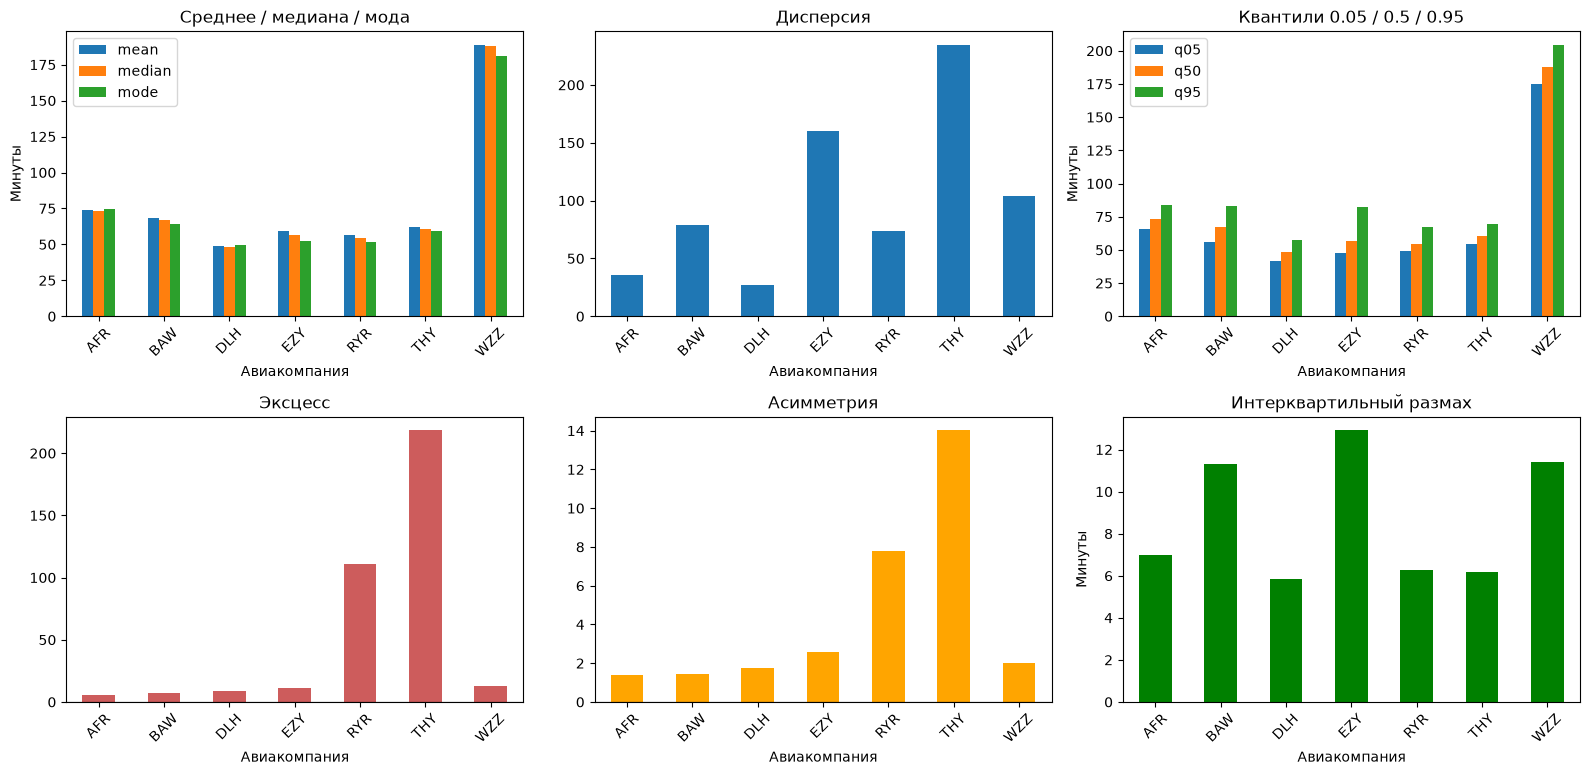

In [21]:
# Самый популярный маршрут для каждой авиакомпании
top_route = (
    df.groupby(['icao_operator', 'adep', 'ades'])
        .size().reset_index(name='count')
        .sort_values(['icao_operator', 'count'], ascending=[True, False])
        .groupby('icao_operator').head(1)
)

# Время полётов
sub = df.merge(top_route[['icao_operator', 'adep', 'ades']],
               on=['icao_operator', 'adep', 'ades'])



# Характеристики
def stats(x):
    return pd.Series({
        'mean':     x.mean(),
        'median':   x.median(),
        'mode':     x.mode().iloc[0],
        'var':      x.var(),
        'q05':      x.quantile(0.05),
        'q50':      x.quantile(0.50),
        'q95':      x.quantile(0.95),
        'kurtosis': x.kurtosis(),
        'skew':     x.skew(),
        'iqr':      x.quantile(0.75) - x.quantile(0.25),
    })

result = (
    sub.groupby('icao_operator')['duration_min']
       .apply(stats).unstack()
)



fig, axes = plt.subplots(2, 3, figsize=(16, 8))

# Среднее, медиана, мода
result[['mean', 'median', 'mode']].plot(kind='bar', ax=axes[0, 0])
axes[0, 0].set_title('Среднее / медиана / мода')
axes[0, 0].set_xlabel('Авиакомпания')
axes[0, 0].set_ylabel('Минуты')

# Дисперсия
result['var'].plot(kind='bar', ax=axes[0, 1])
axes[0, 1].set_title('Дисперсия')
axes[0, 1].set_xlabel('Авиакомпания')

# Квантили
result[['q05', 'q50', 'q95']].plot(kind='bar', ax=axes[0, 2])
axes[0, 2].set_title('Квантили 0.05 / 0.5 / 0.95')
axes[0, 2].set_xlabel('Авиакомпания')
axes[0, 2].set_ylabel('Минуты')

# Эксцесс
result['kurtosis'].plot(kind='bar', ax=axes[1, 0], color='indianred')
axes[1, 0].set_title('Эксцесс')
axes[1, 0].axhline(0, color='black', linewidth=0.8)
axes[1, 0].set_xlabel('Авиакомпания')

# Асимметрия
result['skew'].plot(kind='bar', ax=axes[1, 1], color='orange')
axes[1, 1].set_title('Асимметрия')
axes[1, 1].axhline(0, color='black', linewidth=0.8)
axes[1, 1].set_xlabel('Авиакомпания')

# IQR
result['iqr'].plot(kind='bar', ax=axes[1, 2], color='green')
axes[1, 2].set_title('Интерквартильный размах')
axes[1, 2].set_xlabel('Авиакомпания')
axes[1, 2].set_ylabel('Минуты')

plt.suptitle('')


for ax in axes.flat:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### 2. Постройте графики:
1. гистограмма
2. эмпирические функции распределения
3. Q-Q plot.

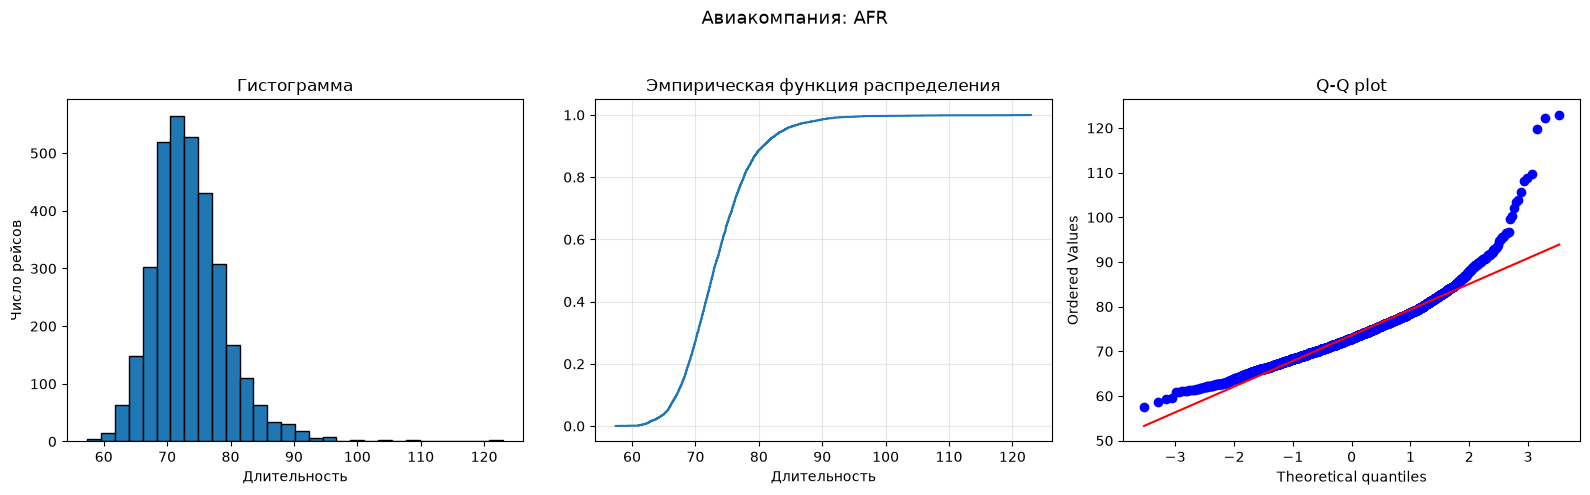

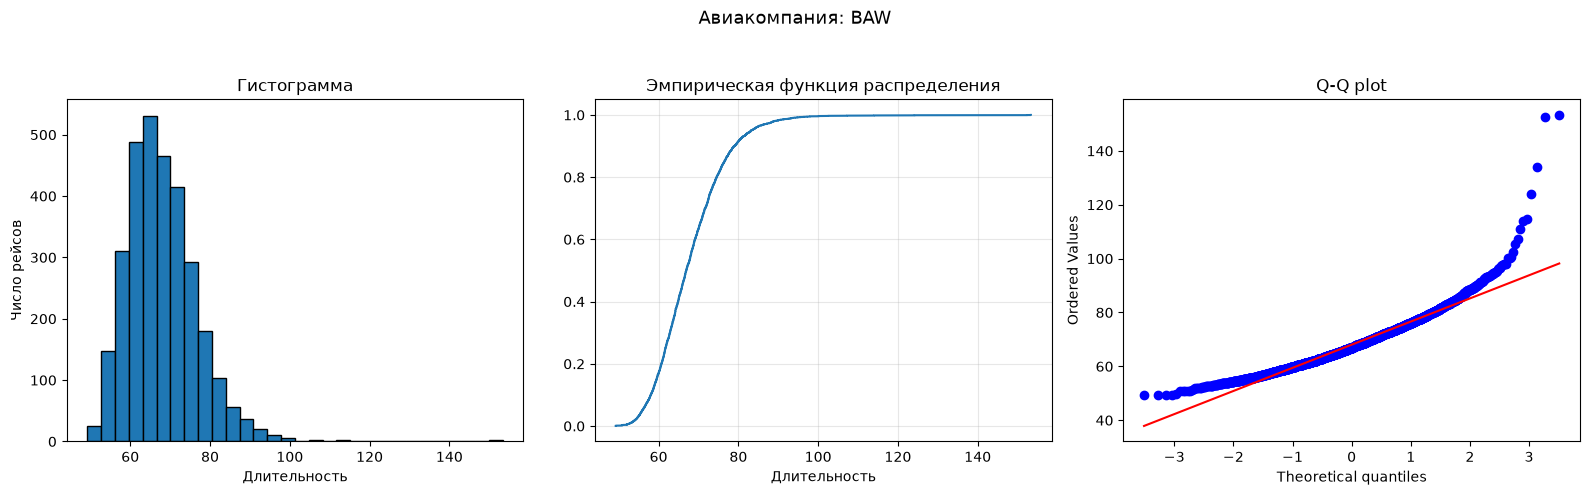

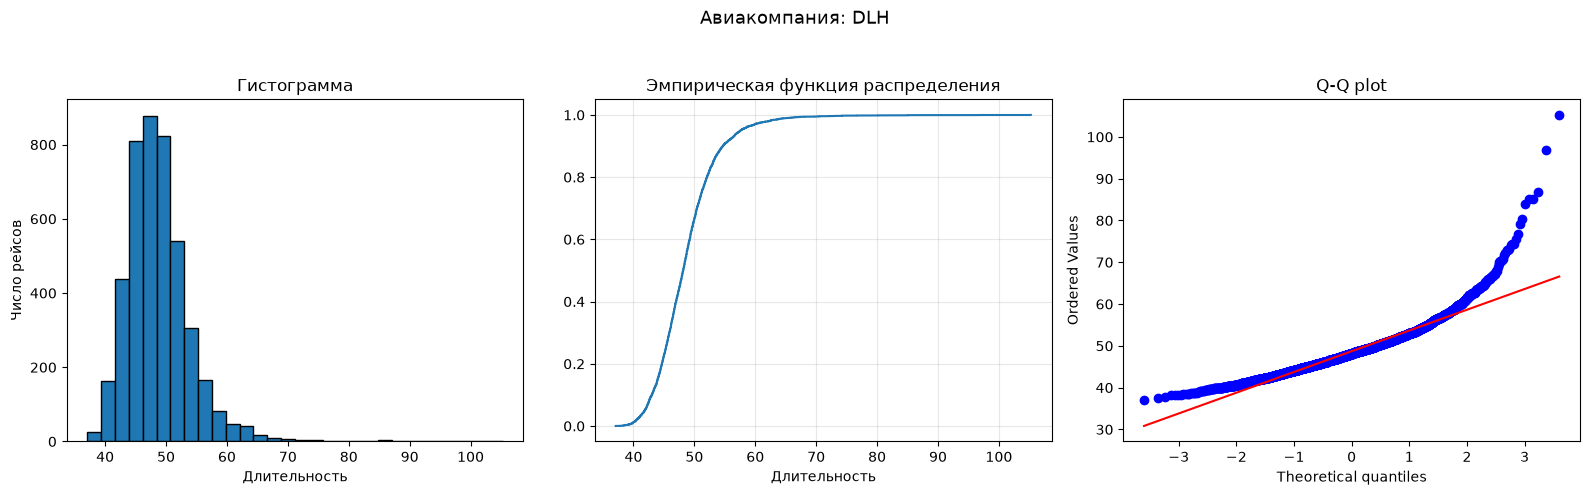

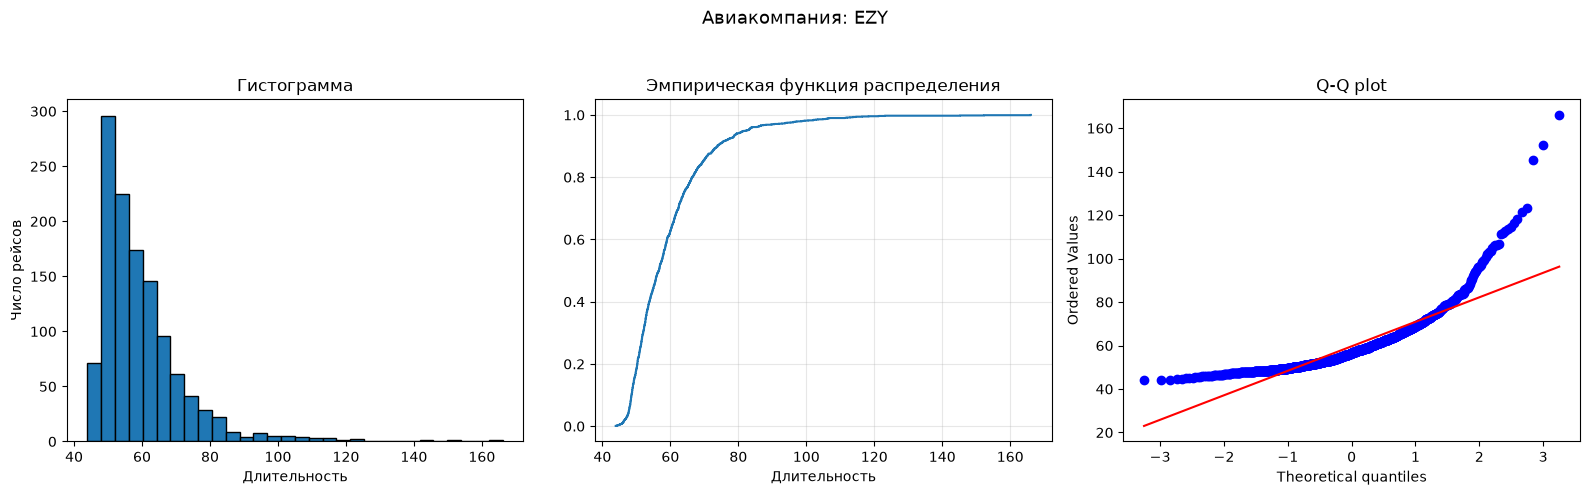

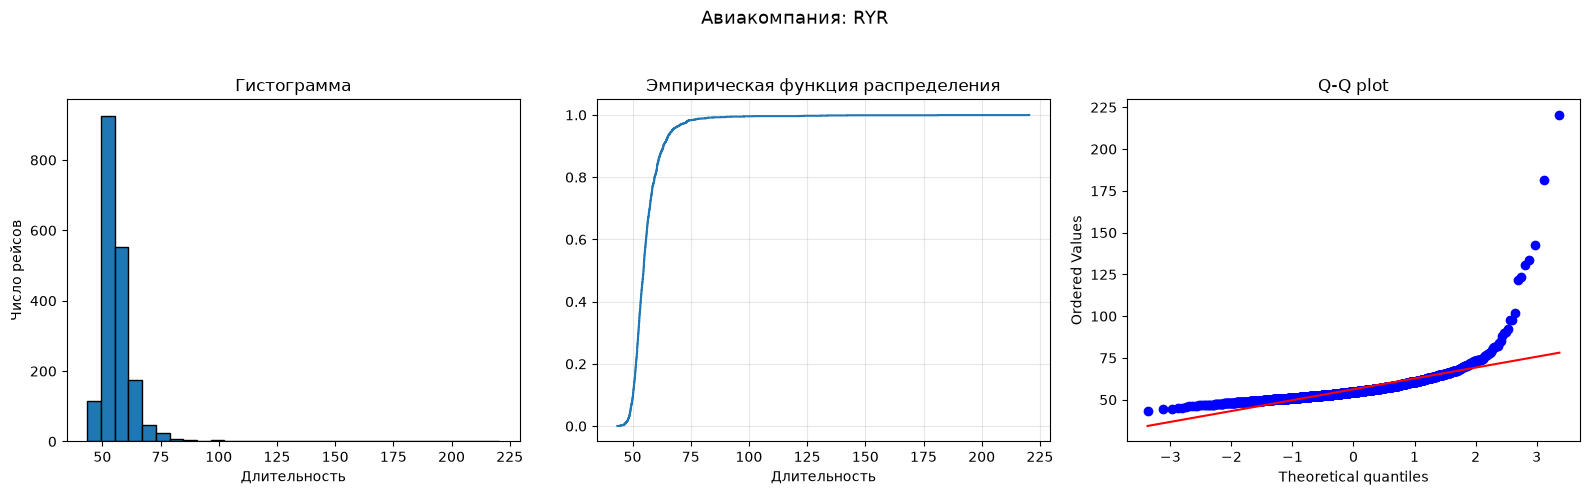

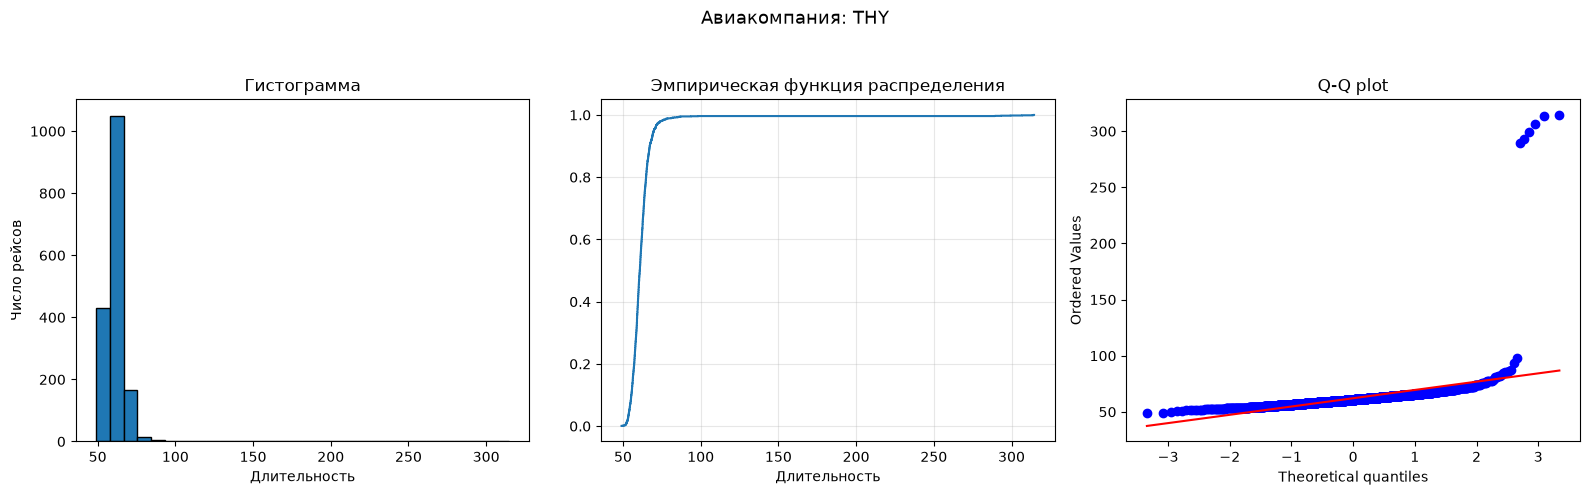

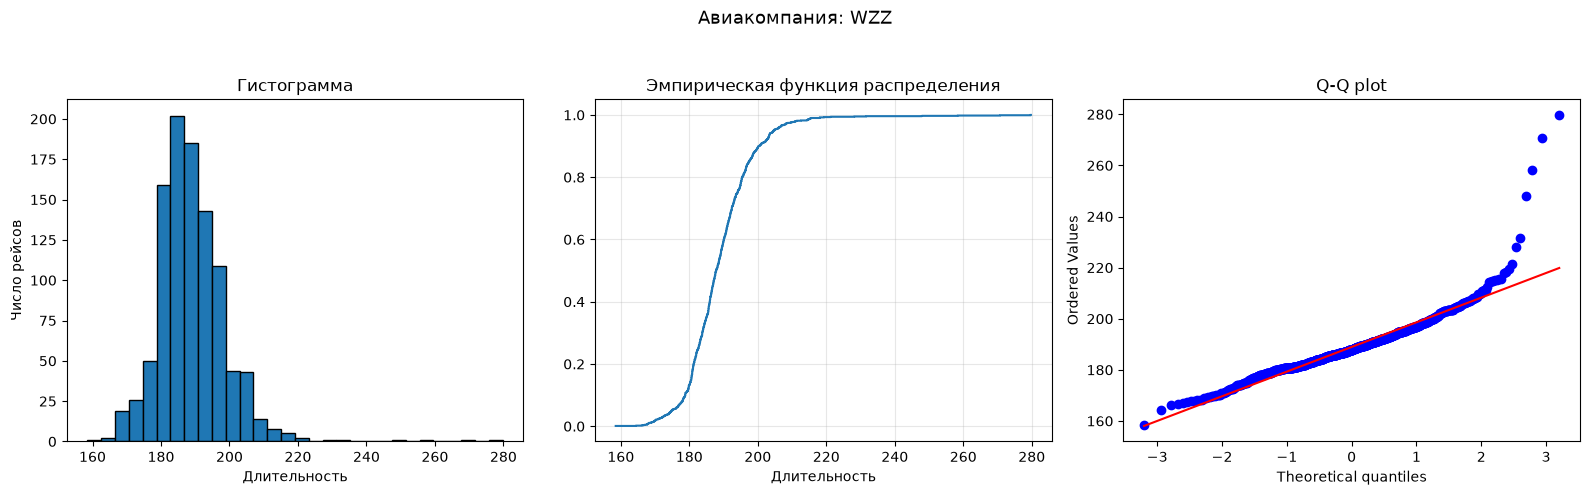

In [22]:
for op, grp in sub.groupby('icao_operator'):
    x = grp['duration_min'].dropna().values

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    # Гистограмма
    axes[0].hist(x, bins=30, edgecolor='black')
    axes[0].set_title('Гистограмма')
    axes[0].set_xlabel('Длительность')
    axes[0].set_ylabel('Число рейсов')

    # Эмпирическая функция распределения
    xs = np.sort(x)
    ys = np.arange(1, len(xs) + 1) / len(xs)
    axes[1].step(xs, ys, where='post')
    axes[1].set_title('Эмпирическая функция распределения')
    axes[1].set_xlabel('Длительность')
    axes[1].grid(alpha=0.3)

    # Q-Q
    sp.stats.probplot(x, dist='norm', plot=axes[2])
    axes[2].set_title('Q-Q plot')

    fig.suptitle(f'Авиакомпания: {op}', fontsize=13)
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()

### 3. Проверьте данные на нормальность:
1. используя Хи-квадрат критерий (реализуйте сами, не используйте библиотечные варианты)
2. критерий ассиметрии и эксцесса

In [23]:
def chi2_normality(x, bins=10):
    x = np.asarray(x)
    n = len(x)
    mu, sigma = x.mean(), x.std(ddof=1)

    edges = sp.stats.norm.ppf(np.linspace(0, 1, bins + 1), mu, sigma)

    O, _ = np.histogram(x, bins=edges)

    E = np.full(bins, n / bins)

    chi2 = ((O - E) ** 2 / E).sum()
    df = bins - 1 - 2
    return chi2, df

rows = []
for op, grp in sub.groupby('icao_operator'):
    x = grp['duration_min'].dropna().values
    if len(x) < 20:
        continue
    chi2_stat, df = chi2_normality(x)
    p_value = 1 - sp.stats.chi2.cdf(chi2_stat, df)
    crit = sp.stats.chi2.ppf(0.95, df)

    rows.append({
        'icao_operator': op,
        'n':       len(x),
        'chi2':    round(chi2_stat, 2),
        'df':      df,
        'crit_95': round(crit, 2),
        'p_value': round(p_value, 5),
        'is_normal': 'нет' if chi2_stat > crit else 'да',
    })

result_chi2 = pd.DataFrame(rows).sort_values('chi2', ascending=False).reset_index(drop=True)
print(result_chi2)

  icao_operator     n     chi2  df  crit_95  p_value is_normal
0           THY  1672  2269.76   7    14.07      0.0       нет
1           RYR  1863   927.58   7    14.07      0.0       нет
2           EZY  1208   430.79   7    14.07      0.0       нет
3           DLH  4368   287.73   7    14.07      0.0       нет
4           AFR  3333   161.16   7    14.07      0.0       нет
5           BAW  3099   130.28   7    14.07      0.0       нет
6           WZZ  1018    82.26   7    14.07      0.0       нет


In [24]:
def skew_kurt_test(x):
    x = np.asarray(x)
    n = len(x)
    A = ((x - x.mean())**3).mean() / x.std(ddof=0)**3
    E = ((x - x.mean())**4).mean() / x.std(ddof=0)**4 - 3

    se_A = np.sqrt(6*n*(n-1) / ((n-2)*(n+1)*(n+3)))
    se_E = np.sqrt(24*n*(n-1)**2 / ((n-3)*(n-2)*(n+3)*(n+5)))

    z_A = A / se_A
    z_E = E / se_E
    JB = n/6 * (A**2 + E**2/4)

    return A, E, z_A, z_E, JB

rows = []
for op, grp in sub.groupby('icao_operator'):
    x = grp['duration_min'].dropna().values
    if len(x) < 20:
        continue

    A, E, z_A, z_E, JB = skew_kurt_test(x)
    p_JB = 1 - sp.stats.chi2.cdf(JB, df=2)
    crit_JB = sp.stats.chi2.ppf(0.95, df=2)

    rows.append({
        'icao_operator': op,
        'n':        len(x),
        'skew':     round(A, 3),
        'kurt':     round(E, 3),
        'z_skew':   round(z_A, 2),
        'z_kurt':   round(z_E, 2),
        'JB':       round(JB, 2),
        'p_JB':     round(p_JB, 5),
        'is_normal':  'нет' if JB > crit_JB else 'да',
    })

result_sk = pd.DataFrame(rows).sort_values('JB', ascending=False).reset_index(drop=True)
print(result_sk)

  icao_operator     n    skew     kurt  z_skew   z_kurt          JB  p_JB  \
0           THY  1672  14.008  217.787  234.06  1820.50  3359042.93   0.0   
1           RYR  1863   7.790  110.223  137.38   972.42   961921.02   0.0   
2           DLH  4368   1.746    8.971   47.12   121.09    16866.28   0.0   
3           BAW  3099   1.447    7.346   32.90    83.54     8049.21   0.0   
4           WZZ  1018   1.987   12.901   25.92    84.23     7729.46   0.0   
5           EZY  1208   2.550   11.096   36.22    78.88     7505.59   0.0   
6           AFR  3333   1.384    5.969   32.64    70.39     6012.27   0.0   

  is_normal  
0       нет  
1       нет  
2       нет  
3       нет  
4       нет  
5       нет  
6       нет  
